# 3. Regresi: Memperkirakan Lama Adopsi

Tujuan: memperkirakan **kecepatan adopsi** (`AdoptionSpeed`) seekor anjing, supaya shelter tahu anjing mana yang kemungkinan lama menunggu dan perlu diprioritaskan promosinya.

Target `AdoptionSpeed`:
- 0 = diadopsi di hari yang sama
- 1 = dalam minggu pertama
- 2 = dalam bulan pertama
- 3 = di bulan kedua atau ketiga
- 4 = belum diadopsi setelah 100 hari

Nilainya kategori yang berurutan (dari cepat ke lambat), jadi bisa diperlakukan sebagai angka untuk regresi linear.

In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

## Membaca data

Profil yang berisi beberapa anjing (`grup = True`) tidak dipakai untuk melatih, karena kecepatan adopsinya dihitung sampai **semua** anjing di profil itu teradopsi.

In [2]:
dogs = pd.read_csv("../data/dogs_clustered.csv")
latih = dogs[~dogs["grup"]].copy()
print("Semua anjing:", len(dogs))
print("Dipakai untuk regresi:", len(latih))

Semua anjing: 6528
Dipakai untuk regresi: 5799


## Fitur

- Angka: umur, ukuran, bulu, kesehatan, biaya, jumlah foto, energi
- Kategori (diubah dengan One-Hot Encoding): jenis kelamin, vaksin, steril

In [3]:
fitur_angka = ["Age", "ukuran_angka", "bulu_angka", "kesehatan_angka", "Fee", "PhotoAmt", "energi"]
fitur_kategori = ["Gender", "Vaccinated", "Sterilized"]
fitur = fitur_angka + fitur_kategori

X = latih[fitur]
y = latih["AdoptionSpeed"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Data latih:", len(X_train), "| Data uji:", len(X_test))

Data latih: 4639 | Data uji: 1160


## Melatih model

In [4]:
model = Pipeline([
    ("prep", ColumnTransformer(
        [("kategori", OneHotEncoder(drop="first", handle_unknown="ignore"), fitur_kategori)],
        remainder="passthrough",
    )),
    ("regresi", LinearRegression()),
])
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('regresi', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Age','ukuran_angka','bulu_angka',...,'Gender','Vaccinated','Sterilized']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('kategori', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatena

## Evaluasi

In [5]:
prediksi = model.predict(X_test)
mae = mean_absolute_error(y_test, prediksi)
r2 = r2_score(y_test, prediksi)

pembanding = mean_absolute_error(y_test, np.full(len(y_test), y_train.mean()))

print(f"MAE  : {mae:.3f}")
print(f"R²   : {r2:.3f}")
print(f"MAE kalau cuma menebak rata-rata: {pembanding:.3f}")

MAE  : 0.962
R²   : 0.067
MAE kalau cuma menebak rata-rata: 1.025


**Cara membaca hasil:**
- **MAE** sekitar 0,96 artinya tebakan model rata-rata meleset kurang dari 1 kategori.
- Model sedikit lebih baik daripada sekadar menebak rata-rata, tapi **R² kecil**. Artinya fitur yang tersedia hanya menjelaskan sebagian kecil alasan anjing cepat atau lambat diadopsi. Faktor besar lain seperti foto, lokasi, dan ras populer tidak ada di dataset ringkas ini.
- Karena itu, hasil regresi di aplikasi dipakai sebagai **urutan prioritas** (mana yang kemungkinan lebih lama), bukan janji waktu yang pasti.

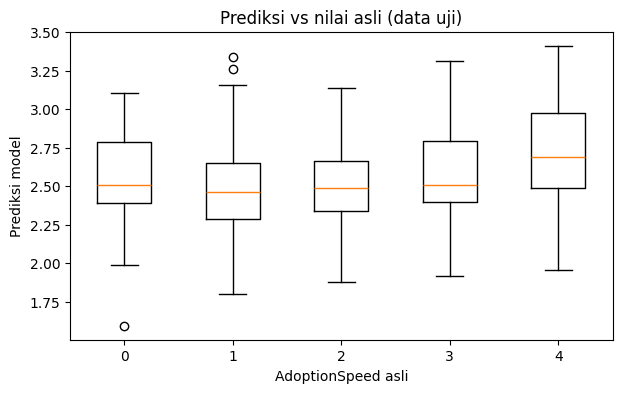

In [6]:
plt.figure(figsize=(7, 4))
data_box = [prediksi[y_test.values == k] for k in range(5)]
plt.boxplot(data_box)
plt.xticks([1, 2, 3, 4, 5], [0, 1, 2, 3, 4])
plt.xlabel("AdoptionSpeed asli")
plt.ylabel("Prediksi model")
plt.title("Prediksi vs nilai asli (data uji)")
plt.show()

## Koefisien: faktor apa yang berpengaruh?

Koefisien positif berarti **memperlambat** adopsi (nilai AdoptionSpeed naik), negatif berarti **mempercepat**.

In [7]:
nama_fitur = model.named_steps["prep"].get_feature_names_out()
koef = pd.Series(model.named_steps["regresi"].coef_, index=nama_fitur).sort_values()
print("Intercept:", round(model.named_steps["regresi"].intercept_, 3))
koef.round(3)

Intercept: 2.507


remainder__bulu_angka           -0.215
kategori__Gender_Male           -0.134
remainder__PhotoAmt             -0.008
kategori__Vaccinated_Not Sure   -0.004
remainder__Fee                  -0.001
remainder__energi                0.001
remainder__Age                   0.001
remainder__ukuran_angka          0.113
kategori__Vaccinated_Yes         0.152
remainder__kesehatan_angka       0.236
kategori__Sterilized_Not Sure    0.371
kategori__Sterilized_Yes         0.454
dtype: float64

## Prediksi untuk semua anjing dan simpan

In [8]:
KATEGORI = ["hari yang sama", "dalam 1 minggu", "dalam 1 bulan", "2–3 bulan", "lebih dari 3 bulan"]

def ke_kategori(nilai):
    return KATEGORI[int(np.clip(round(nilai), 0, 4))]

dogs["prediksi_speed"] = model.predict(dogs[fitur]).round(2)
dogs["perkiraan_adopsi"] = dogs["prediksi_speed"].apply(ke_kategori)

print(dogs["perkiraan_adopsi"].value_counts())

joblib.dump({"model": model, "fitur": fitur, "kategori": KATEGORI}, "../models/regresi.joblib")
dogs.to_csv("../data/dogs_app.csv", index=False)
print("\nModel tersimpan di models/regresi.joblib")
print("Data untuk aplikasi tersimpan di data/dogs_app.csv:", dogs.shape)

perkiraan_adopsi
2–3 bulan             3509
dalam 1 bulan         3016
lebih dari 3 bulan       3
Name: count, dtype: int64

Model tersimpan di models/regresi.joblib
Data untuk aplikasi tersimpan di data/dogs_app.csv: (6528, 26)


## Prioritas promosi: 10 anjing dengan prediksi paling lama

In [9]:
dogs.sort_values("prediksi_speed", ascending=False)[
    ["anjing_id", "Age", "MaturitySize", "Health", "Sterilized", "cluster_label", "prediksi_speed", "perkiraan_adopsi"]
].head(10)

,anjing_id,Age,MaturitySize,Health,Sterilized,cluster_label,prediksi_speed,perkiraan_adopsi
4733,4734,120,Large,Minor Injury,Yes,Dewasa sedang–besar,3.62,lebih dari 3 bulan
3236,3237,120,Large,Serious Injury,Not Sure,Dewasa sedang–besar,3.59,lebih dari 3 bulan
4365,4366,6,Medium,Serious Injury,Yes,Anak anjing bulu pendek,3.56,lebih dari 3 bulan
6491,6492,36,Large,Minor Injury,Yes,Dewasa sedang–besar,3.49,2–3 bulan
3449,3450,60,Medium,Minor Injury,Yes,Dewasa sedang–besar,3.43,2–3 bulan
4590,4591,12,Large,Minor Injury,Yes,Anak anjing bulu pendek,3.42,2–3 bulan
1971,1972,53,Medium,Minor Injury,Yes,Dewasa sedang–besar,3.42,2–3 bulan
5001,5002,60,Medium,Minor Injury,Yes,Dewasa sedang–besar,3.41,2–3 bulan
2574,2575,60,Large,Minor Injury,Yes,Dewasa sedang–besar,3.38,2–3 bulan
2705,2706,36,Large,Minor Injury,Yes,Dewasa sedang–besar,3.38,2–3 bulan
